# 04 — Entrenamiento del modelo de predicción (t+1 por bloques)

**Objetivo**: entrenar el modelo que estima la media de cada bloque horario **del día siguiente**
por (estación, contaminante, bloque), compararlo contra baselines honestos y guardar el bundle que
usará la herramienta de predicción del agente (intent `PREDICCION`, hoy una frase fija).

```
resumen por bloques ──▶ rejilla diaria + lags + calendario objetivo (features_prediccion)
                                   │
                                   ├──▶ baselines: persistencia · climatología · lag semanal
                                   └──▶ HistGradientBoosting por contaminante ──▶ prediccion_bloques.joblib
```

| Baseline | Qué predice para mañana | Columna |
|---|---|---|
| **Persistencia** | lo mismo que se midió hoy en ese bloque | `MEDIA` |
| **Climatología** | el valor típico de ese bloque en el mes de mañana (solo train) | `MEDIA_ESPERADA` |
| **Persistencia semanal** | lo medido hace una semana (mismo día de la semana que mañana) | `MEDIA_LAG_6` |

> **Fuente de datos.** El notebook prefiere el histórico completo
> (`data/processed/resumen_datos_ml.parquet`, 2018–2026, en S3). Si no está en disco, construye los
> bloques desde `data/processed/calidad_aire_live.csv` (≈4 meses reales mantenidos por CI): sirve
> para validar el pipeline de punta a punta y da **cifras provisionales**; el modelo definitivo
> exige reentrenar con el histórico.
>
> **Limitación estructural**: sin datos meteorológicos (viento, lluvia, temperatura), los episodios
> que rompen la persistencia (intrusiones saharianas, inversiones térmicas) son poco predecibles.
> Está documentado como limitación del proyecto; el objetivo realista es batir a la persistencia
> (skill > 0), no predecir episodios.

## 0. Configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor

sys.path.insert(0, str(Path("../src/etl").resolve()))
from features_bloques import a_bloques, calcular_baseline
from features_prediccion import FEATURES_PREDICCION, LAGS, preparar_dataset
from inferencia_prediccion import predecir

# Mismo estilo visual que los notebooks 01-03
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e0e0e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "figure.dpi": 110,
})

# Histórico completo de S3 (cualquiera de los dos parquet de bloques sirve: solo se usan
# ESTACION, MAGNITUD, FECHA, BLOQUE, MEDIA, COBERTURA y MES). Respaldo: el CSV live de CI.
RUTA_PARQUET = next((p for p in [Path("../data/processed/resumen_datos_ml.parquet"),
                                 Path("../data/processed/resumen_bloques.parquet")]
                     if p.exists()), None)
RUTA_LIVE    = Path("../data/processed/calidad_aire_live.csv")      # respaldo: CSV de CI
RUTA_MODELOS = Path("../models/prediccion_bloques.joblib")          # bundle de salida

MAGNITUDES = {7: "NO", 8: "NO2", 9: "PM2.5", 10: "PM10", 12: "NOx", 14: "O3"}
PALETA = {
    "NO2": "#0072B2", "NO": "#56B4E9", "NOx": "#CC79A7",
    "O3": "#009E73", "PM10": "#E69F00", "PM2.5": "#D55E00",
}
ORDEN = ["NO2", "NO", "NOx", "O3", "PM10", "PM2.5"]

HORIZONTE = 1        # días hacia delante (t+1: "mañana")
COBERTURA_MIN = 0.7  # un objetivo con menos horas válidas no es evaluable con garantías
print("Configuración lista.")

Configuración lista.


## 1. Cargar los bloques

Una fila por (estación, magnitud, fecha, bloque) con `MEDIA` y `COBERTURA` — el mismo grano que
produce `a_bloques` y que consume el agente en la vista `mediciones_bloques`.

In [2]:
if RUTA_PARQUET is not None:
    FUENTE = f"histórico completo ({RUTA_PARQUET.name})"
    bloques = pd.read_parquet(RUTA_PARQUET)
    bloques.columns = bloques.columns.str.upper()
    # El parquet trae climatología calculada con TODO el histórico (fuga) y colisiona con
    # el merge de preparar_dataset: se descarta y se recalcula solo con el train.
    bloques = bloques.drop(columns=["MEDIA_ESPERADA", "STD_ESPERADA", "DESVIACION", "Z_SCORE"],
                           errors="ignore")
else:
    FUENTE = "CSV live de CI (PROVISIONAL: ~4 meses)"
    live = pd.read_csv(RUTA_LIVE)
    live = live[live["validacion"] == "V"]
    largo = pd.DataFrame({
        "ESTACION": live["estacion"].astype(int),
        "MAGNITUD": live["magnitud"].astype(int),
        "FECHA": pd.to_datetime(live["fecha"]).dt.date,
        "HORA": live["hora"].astype(int),
        "VALOR": live["valor"].astype(float),
    })
    bloques = a_bloques(largo)

bloques = bloques[bloques["MAGNITUD"].isin(MAGNITUDES)].copy()
bloques["FECHA"] = pd.to_datetime(bloques["FECHA"])
dias = sorted(bloques["FECHA"].dt.date.unique())
huecos = [(a, b) for a, b in zip(dias, dias[1:]) if (b - a).days > 1]
print(f"Fuente: {FUENTE}")
print(f"{len(bloques):,} bloques · {bloques['ESTACION'].nunique()} estaciones · "
      f"{bloques['FECHA'].min():%Y-%m-%d} → {bloques['FECHA'].max():%Y-%m-%d}")
print(f"Huecos de ingesta (días sin datos): {len(huecos)} — la rejilla de features los deja "
      "como NaN y el modelo los ve como tales")

Fuente: histórico completo (resumen_bloques.parquet)
1,274,644 bloques · 24 estaciones · 2018-01-01 → 2026-04-30
Huecos de ingesta (días sin datos): 0 — la rejilla de features los deja como NaN y el modelo los ve como tales


## 2. Corte temporal y climatología sin fuga

Partición **temporal**, nunca aleatoria: el test son los últimos días, como en producción. Dos
precauciones contra la fuga de información:

1. La climatología (`MEDIA_ESPERADA`) se calcula **solo con el train** — la columna equivalente del
   parquet histórico se calculó con todo el histórico y usarla contaminaría el test.
2. En la frontera, una fila de train cuyo objetivo cae en el test se descarta: el train se corta por
   `FECHA_OBJETIVO <= corte` y el test empieza en `FECHA > corte`.

In [3]:
dias_test = 365 if "parquet" in FUENTE else 28
corte = bloques["FECHA"].max() - pd.Timedelta(days=dias_test)

baseline_train = calcular_baseline(bloques[bloques["FECHA"] <= corte])
dataset = preparar_dataset(bloques, baseline_train, HORIZONTE, COBERTURA_MIN)

train = dataset[dataset["FECHA_OBJETIVO"] <= corte].copy()
test  = dataset[dataset["FECHA"] > corte].copy()
print(f"Corte: {corte:%Y-%m-%d}")
print(f"Train: {len(train):,} filas ({train['FECHA'].min():%Y-%m-%d} → {train['FECHA'].max():%Y-%m-%d})")
print(f"Test:  {len(test):,} filas ({test['FECHA'].min():%Y-%m-%d} → {test['FECHA'].max():%Y-%m-%d})")

Corte: 2025-04-30
Train: 1,102,425 filas (2018-01-01 → 2025-04-29)
Test:  153,106 filas (2025-05-01 → 2026-04-29)


## 3. Baselines honestos

Para comparar en igualdad de condiciones, las métricas se calculan sobre el subconjunto del test
donde los **tres** baselines están definidos (la persistencia semanal exige 7 días sin hueco y la
climatología exige que el grupo exista en el train). El modelo se evalúa sobre ese mismo
subconjunto; su resultado sobre el test completo se reporta aparte.

In [4]:
comparable = test[test["MEDIA_LAG_6"].notna() & test["MEDIA_ESPERADA"].notna()].copy()
print(f"Subconjunto comparable: {len(comparable):,} de {len(test):,} filas del test "
      f"({100 * len(comparable) / len(test):.1f}%)")

def mae(y, p):
    return float(np.mean(np.abs(y - p)))

def rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2)))

BASELINES = {"persistencia": "MEDIA", "climatologia": "MEDIA_ESPERADA", "lag_semanal": "MEDIA_LAG_6"}
for nombre, col in BASELINES.items():
    print(f"MAE {nombre:13s}: {mae(comparable['TARGET'], comparable[col]):6.2f} µg/m³")

Subconjunto comparable: 147,790 de 153,106 filas del test (96.5%)
MAE persistencia :  10.46 µg/m³
MAE climatologia :  15.00 µg/m³
MAE lag_semanal  :  13.38 µg/m³


## 4. Modelo: HistGradientBoosting, uno por contaminante

El mismo convenio que el detector (nb03): un modelo por contaminante, guardados juntos en un bundle.
`HistGradientBoostingRegressor` porque ya está en las dependencias del proyecto, **acepta los NaN
de los lags sin imputar** (un hueco de medición es información, no un error) y no necesita
escalado. Descartados: LightGBM (dependencia nueva sin ganancia clara a este tamaño), SARIMA
(una serie por tupla ≈ 550 modelos frágiles con huecos) y LSTM (sin meteorología no hay señal que
justifique PyTorch en CI).

Sin *early stopping*: su validación interna es aleatoria y mezclaría días dentro del train
(fuga temporal leve). Los hiperparámetros se eligen contra una **validación temporal interna**
(las últimas 2 semanas del train), nunca contra el test: con pocos meses de datos, el ajuste
importa — la configuración sin regularizar memoriza el train y pierde contra la persistencia.

In [5]:
# Selección de configuración contra validación interna (temporal, nunca contra el test).
# Ventana proporcional: ~2 meses con el histórico completo, 2 semanas con el CSV provisional.
dias_val = 60 if "parquet" in FUENTE else 14
corte_val = train["FECHA"].max() - pd.Timedelta(days=dias_val)
train_interno = train[train["FECHA_OBJETIVO"] <= corte_val]
validacion = train[train["FECHA"] > corte_val]

CONFIGS = {
    "sin regularizar": dict(max_iter=400, learning_rate=0.05, min_samples_leaf=20),
    "suave":           dict(max_iter=120, learning_rate=0.05, min_samples_leaf=50),
    "muy suave":       dict(max_iter=60, learning_rate=0.05, min_samples_leaf=100, max_depth=3),
    "regularizada L2": dict(max_iter=200, learning_rate=0.04, min_samples_leaf=60, l2_regularization=1.0),
}

def entrenar(filas_train, params):
    por_contaminante = {}
    for mag, nombre in MAGNITUDES.items():
        filas = filas_train[filas_train["MAGNITUD"] == mag]
        if filas.empty:
            continue
        por_contaminante[nombre] = HistGradientBoostingRegressor(
            early_stopping=False, random_state=0, **params,
        ).fit(filas[FEATURES_PREDICCION], filas["TARGET"])
    return por_contaminante

def mae(y, p):
    return float(np.mean(np.abs(y - p)))

print(f"Validación interna: {len(validacion):,} filas "
      f"({validacion['FECHA'].min():%m-%d} → {validacion['FECHA'].max():%m-%d}) · "
      f"MAE persistencia {mae(validacion['TARGET'], validacion['MEDIA']):.2f} µg/m³")
resultados_val = {}
for etiqueta, params in CONFIGS.items():
    candidato = {"modelos": entrenar(train_interno, params),
                 "features": list(FEATURES_PREDICCION), "horizonte": HORIZONTE}
    v = predecir(validacion.copy(), candidato)
    resultados_val[etiqueta] = mae(v["TARGET"], v["PREDICCION"])
    print(f"  {etiqueta:16s} MAE validación: {resultados_val[etiqueta]:.2f} µg/m³")
ELEGIDA = min(resultados_val, key=resultados_val.get)
print(f"Elegida: «{ELEGIDA}»")

Validación interna: 25,487 filas (03-01 → 04-29) · MAE persistencia 8.11 µg/m³


  sin regularizar  MAE validación: 7.46 µg/m³


  suave            MAE validación: 7.43 µg/m³


  muy suave        MAE validación: 7.95 µg/m³


  regularizada L2  MAE validación: 7.43 µg/m³
Elegida: «suave»


In [6]:
# Entrenamiento final con TODO el train y la configuración elegida
modelos = entrenar(train, CONFIGS[ELEGIDA])
print(f"Entrenados {len(modelos)} modelos ({ELEGIDA}) con {len(FEATURES_PREDICCION)} features: "
      f"{FEATURES_PREDICCION}")

bundle = {"modelos": modelos, "features": list(FEATURES_PREDICCION), "horizonte": HORIZONTE,
          "cobertura_min": COBERTURA_MIN, "fecha_corte_train": str(corte.date()),
          "configuracion": {"nombre": ELEGIDA, **CONFIGS[ELEGIDA]}, "fuente": FUENTE}
comparable = predecir(comparable, bundle)
test = predecir(test, bundle)

Entrenados 6 modelos (suave) con 16 features: ['MEDIA', 'MEDIA_LAG_1', 'MEDIA_LAG_2', 'MEDIA_LAG_3', 'MEDIA_LAG_4', 'MEDIA_LAG_5', 'MEDIA_LAG_6', 'MEDIA_MOVIL_3', 'MEDIA_MOVIL_7', 'MEDIA_ESPERADA', 'COBERTURA', 'BLOQUE_ORD', 'ESTACION', 'DIA_SEMANA_OBJ', 'MES_OBJ', 'ES_FIN_SEMANA_OBJ']


## 5. Evaluación

`skill = 1 − MAE_modelo / MAE_persistencia`: positivo = mejor que repetir lo de hoy; 0 = igual;
negativo = peor. El criterio propuesto para dar el modelo por útil: **skill > 0 global y en ≥ 4 de
los 6 contaminantes, y batir a la climatología en todos**.

In [7]:
def tabla_metricas(df, clave):
    filas = []
    for valor, grupo in df.groupby(clave, observed=True):
        fila = {clave: valor, "n": len(grupo)}
        for nombre, col in BASELINES.items():
            fila[f"MAE_{nombre}"] = mae(grupo["TARGET"], grupo[col])
        fila["MAE_modelo"] = mae(grupo["TARGET"], grupo["PREDICCION"])
        fila["RMSE_modelo"] = rmse(grupo["TARGET"], grupo["PREDICCION"])
        fila["skill"] = 1 - fila["MAE_modelo"] / fila["MAE_persistencia"]
        filas.append(fila)
    total = {clave: "GLOBAL", "n": len(df)}
    for nombre, col in BASELINES.items():
        total[f"MAE_{nombre}"] = mae(df["TARGET"], df[col])
    total["MAE_modelo"] = mae(df["TARGET"], df["PREDICCION"])
    total["RMSE_modelo"] = rmse(df["TARGET"], df["PREDICCION"])
    total["skill"] = 1 - total["MAE_modelo"] / total["MAE_persistencia"]
    filas.append(total)
    return pd.DataFrame(filas).round(2)

tabla_contaminante = tabla_metricas(comparable, "CONTAMINANTE").set_index("CONTAMINANTE").loc[ORDEN + ["GLOBAL"]]
tabla_contaminante

,n,MAE_persistencia,MAE_climatologia,MAE_lag_semanal,MAE_modelo,RMSE_modelo,skill
CONTAMINANTE,,,,,,,
NO2,33136,10.24,13.69,13.07,9.46,12.84,0.08
NO,33136,4.80,9.50,5.92,5.66,11.33,-0.18
NOx,33136,17.14,27.23,21.58,16.98,26.92,0.01
O3,18414,15.38,16.65,19.02,13.59,17.15,0.12
PM10,17730,8.17,10.06,11.83,7.51,10.96,0.08
PM2.5,12238,4.22,5.05,5.98,3.89,5.50,0.08
GLOBAL,147790,10.46,15.00,13.38,10.11,16.79,0.03


In [8]:
tabla_bloque = tabla_metricas(comparable, "BLOQUE").set_index("BLOQUE")
print("Por bloque horario:")
display(tabla_bloque)

resto = test.loc[test.index.difference(comparable.index)]
if len(resto):
    print(f"Test completo (incluye {len(resto):,} filas sin algún baseline): "
          f"MAE modelo {mae(test['TARGET'], test['PREDICCION']):.2f} µg/m³")

Por bloque horario:


,n,MAE_persistencia,MAE_climatologia,MAE_lag_semanal,MAE_modelo,RMSE_modelo,skill
BLOQUE,,,,,,,
madrugada,37591,9.60,11.93,12.27,9.32,14.08,0.03
manana,35392,11.56,15.83,13.17,10.20,15.61,0.12
noche,37518,13.79,20.62,18.84,13.90,23.65,-0.01
tarde,37289,6.94,11.66,9.20,7.02,11.09,-0.01
GLOBAL,147790,10.46,15.00,13.38,10.11,16.79,0.03


Test completo (incluye 5,316 filas sin algún baseline): MAE modelo 9.98 µg/m³


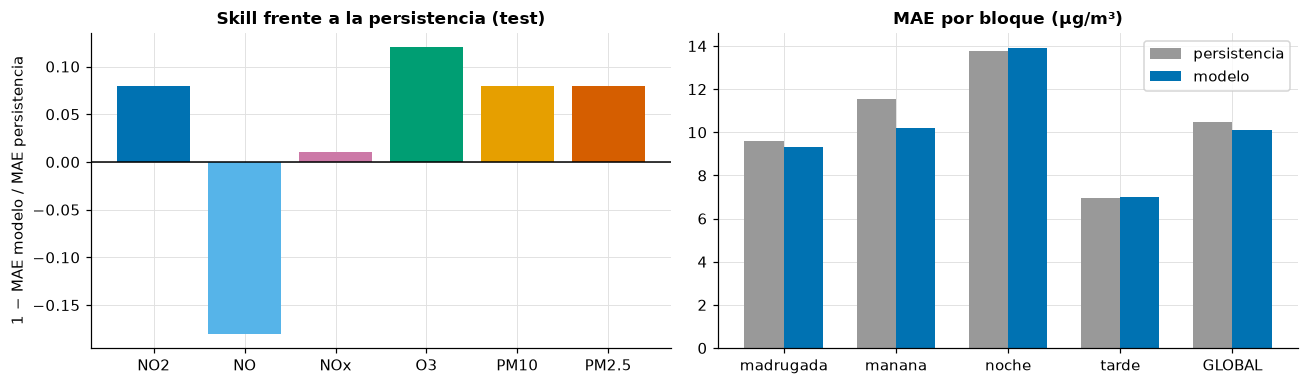

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))

orden_skill = tabla_contaminante.drop(index="GLOBAL")
ejes[0].bar(orden_skill.index, orden_skill["skill"],
            color=[PALETA[c] for c in orden_skill.index])
ejes[0].axhline(0, color="black", linewidth=1)
ejes[0].set_title("Skill frente a la persistencia (test)")
ejes[0].set_ylabel("1 − MAE modelo / MAE persistencia")

ancho = 0.35
x = np.arange(len(tabla_bloque.index))
ejes[1].bar(x - ancho / 2, tabla_bloque["MAE_persistencia"], ancho, label="persistencia", color="#999999")
ejes[1].bar(x + ancho / 2, tabla_bloque["MAE_modelo"], ancho, label="modelo", color="#0072B2")
ejes[1].set_xticks(x, tabla_bloque.index)
ejes[1].set_title("MAE por bloque (µg/m³)")
ejes[1].legend()
plt.tight_layout()
plt.show()

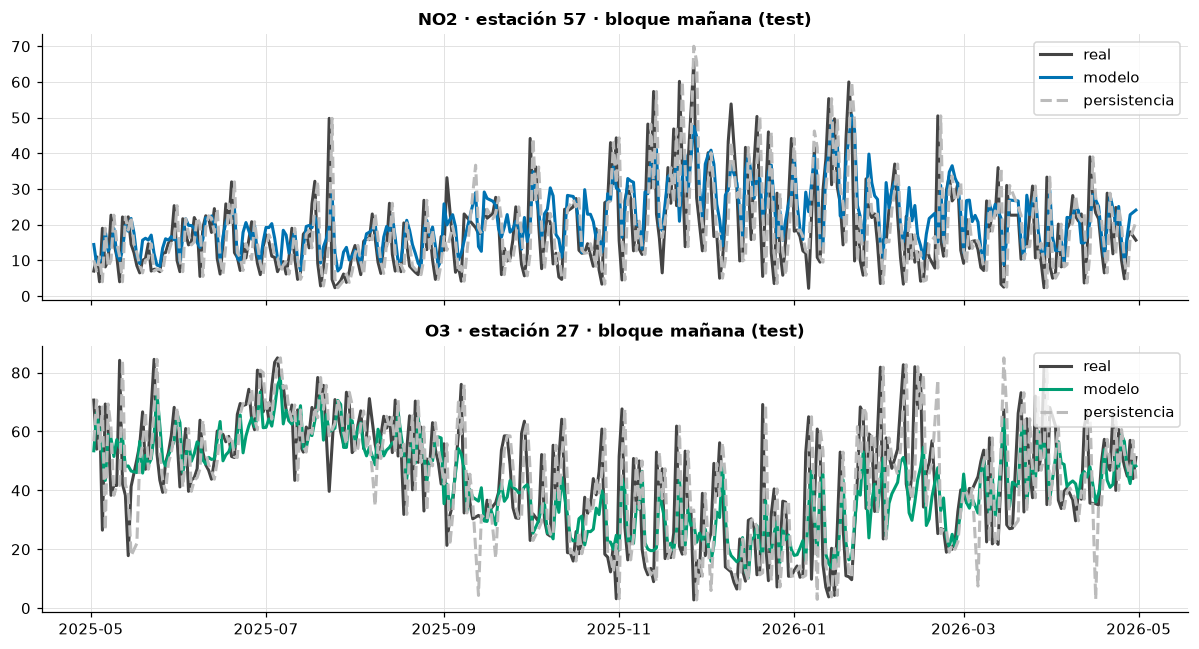

In [10]:
# Dos series de ejemplo en el test: predicho frente a real (bloque mañana)
ejemplos = [("NO2", 8), ("O3", 14)]
fig, ejes = plt.subplots(len(ejemplos), 1, figsize=(11, 3 * len(ejemplos)), sharex=True)
for eje, (nombre, mag) in zip(np.atleast_1d(ejes), ejemplos):
    sub = comparable[(comparable["MAGNITUD"] == mag) & (comparable["BLOQUE"] == "manana")]
    est = sub.groupby("ESTACION").size().idxmax()   # la estación con más días en el test
    serie = sub[sub["ESTACION"] == est].sort_values("FECHA_OBJETIVO")
    eje.plot(serie["FECHA_OBJETIVO"], serie["TARGET"], label="real", color="#444444")
    eje.plot(serie["FECHA_OBJETIVO"], serie["PREDICCION"], label="modelo", color=PALETA[nombre])
    eje.plot(serie["FECHA_OBJETIVO"], serie["MEDIA"], label="persistencia", color="#bbbbbb", linestyle="--")
    eje.set_title(f"{nombre} · estación {est} · bloque mañana (test)")
    eje.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6. ¿Dónde falla? (análisis de errores)

Los peores errores absolutos del test: si el patrón es «subidas bruscas no anticipadas», es la
limitación esperada de un modelo sin meteorología (la persistencia tampoco las ve venir).

Dos hallazgos de calidad del dato que conviene elevar al equipo:
- **Huecos de ingesta** en el CSV de CI (días enteros sin datos, ver §1): degradan los lags y
  encogen el test. La rejilla los trata honestamente (NaN), pero el reentrenamiento definitivo
  debe hacerse sobre el histórico completo, no sobre este CSV.
- **Ceros con flag V**: aparecen bloques con `MEDIA = 0.0` validados (p. ej. PM10 de madrugada)
  seguidos de valores altos. El nb01 documentó los ceros-placeholder con flag `N`; estos pasan el
  filtro por venir marcados como válidos y revientan tanto a la persistencia como al modelo.

In [11]:
peores = comparable.assign(ERROR_ABS=(comparable["TARGET"] - comparable["PREDICCION"]).abs())
cols = ["CONTAMINANTE", "ESTACION", "FECHA_OBJETIVO", "BLOQUE", "MEDIA", "TARGET", "PREDICCION", "ERROR_ABS"]
peores.nlargest(8, "ERROR_ABS")[cols].round(1)

,CONTAMINANTE,ESTACION,FECHA_OBJETIVO,BLOQUE,MEDIA,TARGET,PREDICCION,ERROR_ABS
925275,NOx,54,2026-01-14,noche,73.8,478.5,118.0,360.5
925276,NOx,54,2026-01-15,noche,478.5,36.5,365.0,328.5
925259,NOx,54,2025-12-29,noche,42.2,407.8,92.5,315.3
221388,NOx,17,2026-01-15,noche,354.2,31.8,346.2,314.4
925312,NOx,54,2026-02-20,noche,33.8,369.5,56.9,312.6
221340,NOx,17,2025-11-28,noche,424.2,583.0,276.1,306.9
925228,NOx,54,2025-11-28,noche,198.2,451.2,150.6,300.7
221308,NOx,17,2025-10-27,noche,21.7,342.2,43.8,298.4


## 7. Guardar el bundle

Mismo convenio que `isolation_forest.joblib`: un dict autodescriptivo con los modelos por
contaminante. Lo consumirá `inferencia_prediccion.predecir_manana` (y, en una iteración futura,
la herramienta de predicción del agente). No se escribe nada en S3 ni en la base de datos.

In [12]:
bundle["metricas_test"] = tabla_contaminante.reset_index().to_dict(orient="records")
RUTA_MODELOS.parent.mkdir(exist_ok=True)
joblib.dump(bundle, RUTA_MODELOS)
tamano = RUTA_MODELOS.stat().st_size / 1e6
print(f"Guardado {RUTA_MODELOS} ({tamano:.1f} MB) · horizonte t+{HORIZONTE} · fuente: {FUENTE}")
if "PROVISIONAL" in FUENTE:
    print("AVISO: bundle entrenado con el CSV provisional; reentrenar con el histórico completo "
          "antes de darlo por definitivo.")

Guardado ../models/prediccion_bloques.joblib (2.7 MB) · horizonte t+1 · fuente: histórico completo (resumen_bloques.parquet)


## Conclusiones

1. **Pipeline completo y reproducible**: bloques → features con rejilla anti-hueco → split temporal
   sin fuga (climatología del train, frontera limpia) → baselines → modelo → bundle versionable.
2. **La vara de medir es la persistencia**: en contaminación a 1 día vista es un rival fuerte; el
   `skill` de la tabla del §5 dice cuánto aporta el modelo sobre repetir lo de hoy, contaminante a
   contaminante y bloque a bloque.
3. **Limitaciones**: sin meteorología los episodios bruscos no se anticipan; con la fuente
   provisional (~4 meses) no hay estacionalidad completa y las cifras no son las definitivas; el
   horizonte es t+1 (t+2 está parametrizado pero sin evaluar).
4. **Siguiente paso**: reentrenar con el histórico 2018–2026 (S3), decidir el criterio de éxito
   con el equipo y conectar el bundle a la herramienta `PREDICCION` del agente.